# Shiro Twin: el MDP que decide cuándo aplazar una carga

**Taller 1 · 3.er corte (Aprendizaje por Refuerzo) · Aprendizaje de Máquina 26-2 · Grupo Shiro** · Universidad Sergio Arboleda

## Qué componente de Shiro se construye aquí
El gemelo digital de Shiro ya tiene sus piezas de predicción (simulador lineal con retardos), de clasificación (Guardian,
que anticipa picos) y de agrupamiento (tipos de día). Le falta **la pieza que decide**: el proceso de decisión de Markov
(MDP) sobre el que el agente aprenderá a operar el hogar. Este cuaderno lo formaliza y lo resuelve con iteración de valor,
adaptando el código de las fresas del curso.

## Qué decisiones de arquitectura dependen de este resultado
1. **El espacio de estados**: ¿cabe el tipo de día que encontró K-Means? ¿Hace falta una variable aparte para la
   probabilidad de pico de Guardian?
2. **Si la transición depende de la acción.** En el ejemplo de las fresas no depende, y por eso su política óptima es
   exactamente la codiciosa. En Shiro, aplazar una carga **deja una carga pendiente** que habrá que ejecutar después: el
   futuro sí cambia.
3. **Cuánto vale una hora de espera (λ)**, el parámetro que la persona ajustaría y que decide si aplazar compensa.
4. **Qué hace el agente en estados poco vistos.**

## Reglas fijadas antes de calcular
- Partición **temporal**: todo lo que se estima (centroides, recompensas, transiciones) sale de enero–abril; mayo se usa
  solo para evaluar.
- Cada cifra de mayo va con su par de enero–abril.
- Ninguna cifra está escrita a mano: el cuaderno las guarda en `cifras.json`, la fuente única del documento y de la
  presentación.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
warnings.filterwarnings("ignore")
%matplotlib inline

# --- PARÁMETROS DE EJECUCIÓN ---
RS = 42                       # semilla en todo el proyecto
CORTE = pd.Timestamp("2016-04-30")   # entrenamiento hasta el 30-abr; mayo es la prueba
UMBRAL = 200                  # Wh por lectura de 10 min (convención del proyecto: p90 de entrenamiento)
NIVEL_BAJO = 60               # mediana de las lecturas
HORA_TIPO = 8                 # antes de esta hora el tipo de día no es observable (C2-T2)
GAMMA = 0.95                  # descuento por hora
THETA = 1e-6                  # umbral de convergencia (las recompensas que importan son ~0,06 kWh-eq)
R_PUNTA = 1.5                 # tarifa de punta relativa al valle (valle = 1,0)
F_DESPL = 0.40                # fracción desplazable del exceso sobre 200 Wh (hallazgo 31: 39,7 %)
LAMBDA = 0.005                # costo de una hora con carga esperando (kWh-eq); supuesto, se barre abajo
LAMBDAS = [0.0, 0.002, 0.005, 0.01, 0.02]
R_PUNTAS = [1.0, 1.25, 1.5, 2.0]
GAMMAS = [0.0, 0.5, 0.9, 0.95, 0.99]

RUTA_CSV = Path("../../data set/energydata_complete.csv")
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
COL = {"No actuar": "#8C8C8C", "Aplazar": "#2E75B6", "Ejecutar": "#C55A11"}
AZUL = "#1F3864"

CIFRAS = {}
def es(x, dec=1):
    """Formato es-CO: coma decimal, punto de miles, signo menos tipográfico."""
    s = f"{abs(x):,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return ("\u2212" if (x < 0 and round(abs(x), dec) != 0) else "") + s
def reg(clave, valor, texto):
    CIFRAS[clave] = {"valor": valor if not isinstance(valor, (np.floating, np.integer)) else valor.item(), "texto": texto}
    return texto
print("Parámetros listos.")

Parámetros listos.


## PASO 1 · Cargar y limpiar los datos

El ejemplo de las fresas trabaja por **semana**; Shiro decide por **hora**. A 10 minutos dos lecturas seguidas son casi
idénticas (autocorrelación) y la tabla de transiciones sería casi la identidad; además, aplazar una lavadora o un horno
se decide a escala de horas. Se usan los **136 días completos** (144 lecturas cada uno) y se agregan a 24 horas por día.

In [2]:
print("--- PASO 1: Cargando y limpiando datos ---")
df = pd.read_csv(RUTA_CSV, parse_dates=["date"])
df["dia"] = df["date"].dt.normalize(); df["hora"] = df["date"].dt.hour
lecturas = df.groupby("dia").size()
DIAS = lecturas[lecturas == 144].index
d = df[df["dia"].isin(DIAS)].copy()
d["exceso"] = (d["Appliances"] - UMBRAL).clip(lower=0)

# Serie horaria: media de las 6 lecturas (Wh por 10 min), energía de la hora (Wh) y exceso sobre 200 Wh (Wh)
H = (d.groupby(["dia", "hora"])
       .agg(media=("Appliances", "mean"), wh=("Appliances", "sum"), exceso=("exceso", "sum"))
       .reset_index().sort_values(["dia", "hora"]).reset_index(drop=True))
H["ts"] = H["dia"] + pd.to_timedelta(H["hora"], unit="h")
H["train"] = H["dia"] <= CORTE
DIAS_TR = [x for x in DIAS if x <= CORTE]; DIAS_TE = [x for x in DIAS if x > CORTE]

assert len(df) == 19735 and len(DIAS) == 136, "El dataset no coincide con el del proyecto"
assert len(DIAS_TR) == 110 and len(DIAS_TE) == 26
print(f"Lecturas: {len(df)} · días completos: {len(DIAS)} (entrenamiento {len(DIAS_TR)}, prueba {len(DIAS_TE)})")
print(f"Horas: {len(H)} (entrenamiento {H.train.sum()}, prueba {(~H.train).sum()})")
reg("n_dias", len(DIAS), es(len(DIAS), 0)); reg("n_dias_tr", len(DIAS_TR), es(len(DIAS_TR), 0))
reg("n_dias_te", len(DIAS_TE), es(len(DIAS_TE), 0)); reg("n_horas_tr", int(H.train.sum()), es(int(H.train.sum()), 0))
reg("n_horas_te", int((~H.train).sum()), es(int((~H.train).sum()), 0))

--- PASO 1: Cargando y limpiando datos ---


Lecturas: 19735 · días completos: 136 (entrenamiento 110, prueba 26)
Horas: 3264 (entrenamiento 2640, prueba 624)


'624'

### PASO 1.5 · Gráfica de justificación

En las fresas, la gráfica de precios mostraba que ninguna ciudad es siempre la mejor. Aquí la pregunta equivalente es si
**hay algo que mover**: si el consumo alto se concentrara en la madrugada (tarifa de valle), aplazar no serviría de
nada.

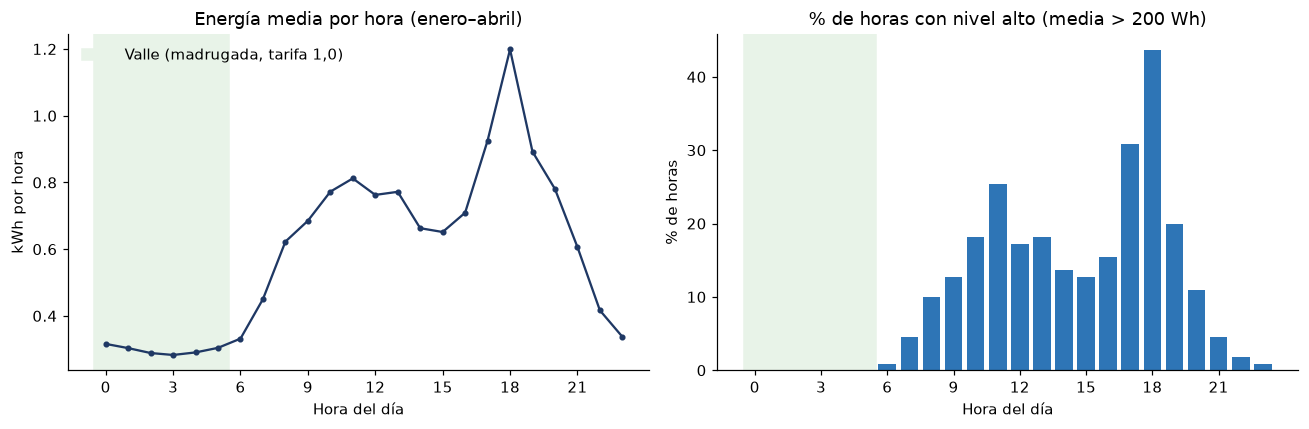

Horas con nivel alto en entrenamiento: 10.9 %; de ellas, en la madrugada: 0.0 %


'0,0 %'

In [3]:
tr = H[H.train]
perfil = tr.groupby("hora")["wh"].mean()
p_alto = tr.assign(alto=tr["media"] > UMBRAL).groupby("hora")["alto"].mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].axvspan(-0.5, 5.5, color="#E8F3E8", label="Valle (madrugada, tarifa 1,0)")
ax[0].plot(perfil.index, perfil.values / 1000, color=AZUL, marker="o", ms=3)
ax[0].set(title="Energía media por hora (enero–abril)", xlabel="Hora del día", ylabel="kWh por hora", xticks=range(0, 24, 3))
ax[0].legend(loc="upper left", frameon=False)
ax[1].axvspan(-0.5, 5.5, color="#E8F3E8")
ax[1].bar(p_alto.index, p_alto.values, color="#2E75B6")
ax[1].set(title="% de horas con nivel alto (media > 200 Wh)", xlabel="Hora del día", ylabel="% de horas", xticks=range(0, 24, 3))
fig.tight_layout(); fig.savefig(FIG / "R1_justificacion.png"); plt.show()
alto_valle = (tr["media"] > UMBRAL)[tr.hora < 6].sum() / (tr["media"] > UMBRAL).sum() * 100
print(f"Horas con nivel alto en entrenamiento: {(tr['media'] > UMBRAL).mean()*100:.1f} %; de ellas, en la madrugada: {alto_valle:.1f} %")
reg("pct_horas_alto_tr", float((tr["media"] > UMBRAL).mean() * 100), es((tr["media"] > UMBRAL).mean() * 100) + " %")
reg("pct_alto_en_valle", float(alto_valle), es(alto_valle) + " %")

## PASO 2 · Definir los estados (S): aquí entra el aprendizaje no supervisado

**Se elimina el `pd.qcut` del ejemplo.** El estado es la información mínima que Shiro necesita para decidir:

| Variable | Valores | De dónde sale |
|---|---|---|
| **Tipo de día estimado** | normal / carga alta | **K-Means k = 2** del Taller 2 del 2.º corte, ajustado solo con los días de entrenamiento. Se asigna con la curva del día **vista hasta la hora anterior** (centroide más cercano sobre esas horas); antes de las 8 h es «normal», porque hasta esa hora asignar con la curva parcial era peor que no asignar. |
| **Franja** | madrugada · mañana · tarde · noche | Hora del día en bloques de 6 h. Define la tarifa. |
| **Nivel de demanda** | bajo (< 60 Wh) · medio · alto (> 200 Wh) | Media de lecturas de la hora en curso; 200 Wh es el umbral de anomalía del proyecto. |
| **Carga pendiente** | no / sí | No sale del dataset: la crea la acción «Aplazar». |

**Por qué estas cuatro y no veinte (maldición de la dimensionalidad).** Con 3 variables exógenas hay 2 × 4 × 3 = 24
combinaciones, y la tabla de cobertura de abajo muestra cuántas veces se visitó cada una. Con la hora (24 valores) en
lugar de la franja serían 288, y las transiciones no se podrían estimar con 110 días. La probabilidad de pico de Guardian
(G0) no necesita variable propia: sus dos entradas, consumo actual y hora × laborable, ya son *nivel* y *franja*.

In [4]:
print("--- PASO 2: Definiendo estados (S) ---")
NIVEL_DIA = H.pivot(index="dia", columns="hora", values="media")          # 136 días × 24 h (Wh por lectura)
km = KMeans(n_clusters=2, n_init=10, random_state=RS).fit(NIVEL_DIA.loc[DIAS_TR].values)
C = km.cluster_centers_; ALTO = int(np.argmax(C.sum(1)))

# .predict() del modelo de clustering sobre el día completo (referencia, mira el día entero)
tipo_completo = pd.Series((km.predict(NIVEL_DIA.values) == ALTO).astype(int), index=NIVEL_DIA.index)
n_alto_tr = int(tipo_completo.loc[DIAS_TR].sum()); n_alto_te = int(tipo_completo.loc[DIAS_TE].sum())
print(f"Centroides: {C.sum(1)[1-ALTO]*6/1000:.1f} y {C.sum(1)[ALTO]*6/1000:.1f} kWh/día")
print(f"Días de carga alta: entrenamiento {n_alto_tr}/{len(DIAS_TR)} ({n_alto_tr/len(DIAS_TR)*100:.1f} %), mayo {n_alto_te}/{len(DIAS_TE)} ({n_alto_te/len(DIAS_TE)*100:.1f} %)")

# Asignación en línea: la misma regla del centroide más cercano, restringida a las horas ya vistas
def tipo_estimado(curva, h):
    if h < HORA_TIPO:
        return 0
    dist = ((C[:, :h] - curva[:h]) ** 2).sum(1)
    return int(np.argmin(dist) == ALTO)
H["tipo"] = [tipo_estimado(NIVEL_DIA.loc[dd].values, hh) for dd, hh in zip(H.dia, H.hora)]
H["franja"] = H["hora"] // 6
H["nivel"] = np.select([H["media"] < NIVEL_BAJO, H["media"] <= UMBRAL], [0, 1], 2)
H["x"] = H["tipo"].astype(str) + "-" + H["franja"].astype(str) + "-" + H["nivel"].astype(str)

TIPO_N = {0: "normal", 1: "carga alta"}; FRANJA_N = {0: "madrugada", 1: "mañana", 2: "tarde", 3: "noche"}
NIVEL_N = {0: "bajo", 1: "medio", 2: "alto"}
def partes(x): return tuple(int(v) for v in x.split("-")[:3])
def describir(s):
    t, f, n = partes(s); txt = f"{TIPO_N[t]} · {FRANJA_N[f]} · {NIVEL_N[n]}"
    return txt + (" · con carga pendiente" if s.count("-") == 3 and s.endswith("-1") else "")

# Observabilidad: ¿cuántos días de carga alta reconoce la curva parcial a las 12 h y a las 18 h?
for hh in (12, 18):
    acierto = np.mean([tipo_estimado(NIVEL_DIA.loc[dd].values, hh) == tipo_completo.loc[dd] for dd in DIAS_TR]) * 100
    rec = np.mean([tipo_estimado(NIVEL_DIA.loc[dd].values, hh) for dd in DIAS_TR if tipo_completo.loc[dd] == 1]) * 100
    print(f"Curva hasta las {hh} h: coincide con el día completo en {acierto:.1f} % de los días; reconoce {rec:.1f} % de los de carga alta")
    reg(f"obs_rec_{hh}", float(rec), es(rec) + " %")

TR = H[H.train]; TE = H[~H.train]
vis = TR["x"].value_counts()
X_EXO = sorted(vis.index)
print(f"\nCombinaciones exógenas vistas en entrenamiento: {len(X_EXO)} de 24 · visitas: mínimo {vis.min()}, mediana {int(vis.median())}")
print("Estados nuevos en mayo (no vistos en entrenamiento):", sorted(set(TE.x) - set(X_EXO)) or "ninguno")
print("Pocas visitas (< 15):", {describir(k): int(v) for k, v in vis[vis < 15].items()})
autolazo_h = (TR["x"].values[1:] == TR["x"].values[:-1]).mean()
s10 = (d["hora"] // 6).astype(str) + "-" + np.select([d["Appliances"] < NIVEL_BAJO, d["Appliances"] <= UMBRAL], ["0", "1"], "2")
autolazo_10 = (s10.values[1:] == s10.values[:-1]).mean()
print(f"Probabilidad de repetir estado en el paso siguiente: {autolazo_10:.2f} a 10 min frente a {autolazo_h:.2f} por hora")

reg("km_kwh_normal", float(C.sum(1)[1-ALTO]*6/1000), es(C.sum(1)[1-ALTO]*6/1000) + " kWh/día")
reg("km_kwh_alto", float(C.sum(1)[ALTO]*6/1000), es(C.sum(1)[ALTO]*6/1000) + " kWh/día")
reg("n_alto_tr", n_alto_tr, es(n_alto_tr, 0)); reg("n_alto_te", n_alto_te, es(n_alto_te, 0))
reg("pct_alto_tr", n_alto_tr/len(DIAS_TR)*100, es(n_alto_tr/len(DIAS_TR)*100) + " %")
reg("pct_alto_te", n_alto_te/len(DIAS_TE)*100, es(n_alto_te/len(DIAS_TE)*100) + " %")
reg("n_x_vistos", len(X_EXO), es(len(X_EXO), 0)); reg("vis_min", int(vis.min()), es(int(vis.min()), 0))
reg("vis_med", int(vis.median()), es(int(vis.median()), 0)); reg("n_x_nuevos_te", len(set(TE.x) - set(X_EXO)), es(len(set(TE.x) - set(X_EXO)), 0))
reg("estado_min", describir(vis.idxmin()), describir(vis.idxmin()))
reg("autolazo_10", float(autolazo_10), es(autolazo_10, 2)); reg("autolazo_h", float(autolazo_h), es(autolazo_h, 2))
reg("n_estados", 2 * len(X_EXO), es(2 * len(X_EXO), 0))

--- PASO 2: Definiendo estados (S) ---


Centroides: 12.3 y 20.7 kWh/día
Días de carga alta: entrenamiento 25/110 (22.7 %), mayo 3/26 (11.5 %)


Curva hasta las 12 h: coincide con el día completo en 87.3 % de los días; reconoce 80.0 % de los de carga alta
Curva hasta las 18 h: coincide con el día completo en 100.0 % de los días; reconoce 100.0 % de los de carga alta

Combinaciones exógenas vistas en entrenamiento: 20 de 24 · visitas: mínimo 4, mediana 74
Estados nuevos en mayo (no vistos en entrenamiento): ninguno
Pocas visitas (< 15): {'carga alta · mañana · bajo': 9, 'carga alta · tarde · bajo': 4}
Probabilidad de repetir estado en el paso siguiente: 0.73 a 10 min frente a 0.60 por hora


'40'

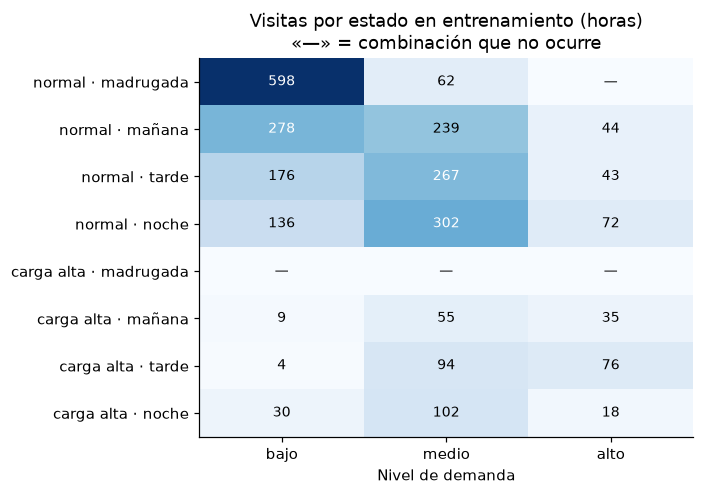

In [5]:
# Tabla de cobertura (visitas por combinación exógena en entrenamiento)
cob = np.full((8, 3), np.nan)
for x, v in vis.items():
    t, f, n = partes(x); cob[t * 4 + f, n] = v
fig, ax = plt.subplots(figsize=(6.5, 4.6))
im = ax.imshow(np.nan_to_num(cob, nan=0), cmap="Blues", aspect="auto")
for i in range(8):
    for j in range(3):
        ax.text(j, i, "—" if np.isnan(cob[i, j]) else int(cob[i, j]), ha="center", va="center",
                color="white" if (not np.isnan(cob[i, j]) and cob[i, j] > 250) else "black", fontsize=9)
ax.set_xticks(range(3), [NIVEL_N[n] for n in range(3)]); ax.set_xlabel("Nivel de demanda")
ax.set_yticks(range(8), [f"{TIPO_N[t]} · {FRANJA_N[f]}" for t in (0, 1) for f in range(4)])
ax.set_title("Visitas por estado en entrenamiento (horas)\n«—» = combinación que no ocurre")
fig.tight_layout(); fig.savefig(FIG / "R2_cobertura.png"); plt.show()

## PASO 3 · Recompensas (R) y transiciones (P)

### 3a · Recompensa: ahorro menos el costo de esperar

Acciones: **No actuar**, **Aplazar** la carga desplazable (solo con nivel alto y sin otra pendiente: hay un solo cupo) y
**Ejecutar** la carga pendiente. La acción «ajustar la consigna ±1 °C» de la propuesta **se deja fuera**: el dataset no
trae un actuador térmico ni un dato que mida su efecto, y modelarla sería inventar la física.

- **Energía desplazable ΔE** = 40 % del exceso medio sobre 200 Wh en las horas de nivel alto. El 40 % viene del Parcial 2:
  solo el 39,7 % del exceso del mes estaba en picos avisables.
- **Tarifa**: valle (madrugada) = 1,0; punta (resto del día) = 1,5. Unidad: **kWh-equivalentes de valle**.
- **λ** = costo de cada hora con la carga esperando (0,005 kWh-eq por defecto; se barre en la Parte 3).

**Contabilidad de la carga aplazada (decisión de diseño).** Con descuento γ < 1, pagar después *parece* más barato que
pagar ahora. Si la energía aplazada se cobrara completa al ejecutarla, el agente aplazaría aunque la tarifa fuera plana:
estaría aprovechando el descuento, no la tarifa (el «ahorro simulado que no existe» del hallazgo 3). Por eso:
- al **aplazar** se cobra de inmediato la parte inevitable, ΔE al precio de valle;
- al **ejecutar** solo se cobra el sobrecosto frente al valle.

La suma sin descontar es idéntica; lo único que cambia es que el descuento ya no premia postergar. La sección 3.4 lo
comprueba con la tarifa plana.

In [6]:
print("--- PASO 3a: Construyendo R(s, a) ---")
ACCIONES = ["No actuar", "Aplazar", "Ejecutar"]
E_DEM = TR.groupby("x")["wh"].mean().to_dict()                 # Wh por hora en cada estado exógeno (como el groupby del ejemplo)
DE = F_DESPL * TR.loc[TR.nivel == 2, "exceso"].mean()          # Wh que se pueden mover en una hora de nivel alto
print(f"Exceso medio sobre 200 Wh en horas de nivel alto: {TR.loc[TR.nivel == 2, 'exceso'].mean():.0f} Wh → ΔE = {DE:.0f} Wh")
reg("exceso_alto", float(TR.loc[TR.nivel == 2, "exceso"].mean()), es(TR.loc[TR.nivel == 2, "exceso"].mean(), 0) + " Wh")
reg("DE", float(DE), es(DE, 0) + " Wh")

STATES = [f"{x}-{p}" for x in X_EXO for p in (0, 1)]
def tarifa(f, r_punta): return 1.0 if f == 0 else r_punta
def valida(s, a):
    t, f, n = partes(s); p = int(s[-1])
    return a == 0 or (a == 1 and n == 2 and p == 0) or (a == 2 and p == 1)
def pendiente_tras(s, a):
    return 1 if a == 1 else (0 if a == 2 else int(s[-1]))

def construir_R(r_punta=R_PUNTA, lam=LAMBDA, contabilidad="corregida"):
    R = {}
    for s in STATES:
        x = s[:-2]; t, f, n = partes(s); tar = tarifa(f, r_punta)
        e, de = E_DEM[x] / 1000, DE / 1000
        R[s] = {}
        for a in range(3):
            if not valida(s, a):
                continue
            if contabilidad == "corregida":
                costo = [tar * e, tar * (e - de) + 1.0 * de, tar * e + (tar - 1.0) * de][a]
            else:   # ingenua: la energía aplazada se paga completa cuando se ejecuta
                costo = [tar * e, tar * (e - de), tar * (e + de)][a]
            R[s][a] = -costo - lam * pendiente_tras(s, a)
    return R

R_dict = construir_R()
print(f"Estados del MDP: {len(STATES)} ({len(X_EXO)} combinaciones exógenas × carga pendiente sí/no)")
print("Ejemplo, R(s, a) en «normal · noche · alto · sin pendiente»:", {ACCIONES[a]: round(v, 4) for a, v in R_dict["0-3-2-0"].items()})

--- PASO 3a: Construyendo R(s, a) ---
Exceso medio sobre 200 Wh en horas de nivel alto: 776 Wh → ΔE = 310 Wh
Estados del MDP: 40 (20 combinaciones exógenas × carga pendiente sí/no)
Ejemplo, R(s, a) en «normal · noche · alto · sin pendiente»: {'No actuar': -2.5331, 'Aplazar': np.float64(-2.383)}


### 3b · Transición: conteo histórico más el efecto de la acción

P(s'|s,a) = P_datos(x'|x) · P_acción(p'|p,a).
- **P_datos (Opción A, como en el ejemplo):** se cuenta con `shift(-1)` cuántas veces la hora siguiente cayó en cada
  combinación (tipo, franja, nivel), solo en entrenamiento.
- **P_acción (determinista):** aplazar deja la carga pendiente, ejecutar la libera y no actuar la mantiene.

Supuesto declarado: lo que el hogar *demanda* no depende de que Shiro aplace, es decir, aplazar no cambia lo demás que la
gente enciende.

In [7]:
print("--- PASO 3b: Construyendo P(s' | s, a) ---")
sig = H[["x", "ts", "train"]].shift(-1)
pares = H[(H.train) & (sig.train == True) & ((sig.ts - H.ts) == pd.Timedelta(hours=1))].assign(x_sig=sig.x)
conteo = pares.groupby(["x", "x_sig"]).size().to_frame("count")
total = pares.groupby("x").size().to_frame("total_s_visits")
P_tabla = conteo.join(total, on="x"); P_tabla["prob"] = P_tabla["count"] / P_tabla["total_s_visits"]
P_EXO = {x: {} for x in X_EXO}
for (x, x2), row in P_tabla.iterrows():
    P_EXO[x][x2] = row["prob"]
print(f"Transiciones contadas: {len(pares)} · pares (s, s') distintos: {len(P_tabla)}")

P_dict = {}
for s in STATES:
    x = s[:-2]; P_dict[s] = {}
    for a in range(3):
        if valida(s, a):
            p2 = pendiente_tras(s, a)
            P_dict[s][a] = {f"{x2}-{p2}": pr for x2, pr in P_EXO[x].items()}
assert all(abs(sum(P_dict[s][a].values()) - 1) < 1e-9 for s in STATES for a in P_dict[s])
reg("n_pares_P", len(P_tabla), es(len(P_tabla), 0))

# Horas esperadas hasta el valle desde cada combinación (tiempo de primer paso de la cadena contada)
objetivo = [x for x in X_EXO if partes(x)[1] == 0]; resto = [x for x in X_EXO if x not in objetivo]
Q_ = np.array([[P_EXO[x].get(x2, 0) for x2 in resto] for x in resto])
m = np.linalg.solve(np.eye(len(resto)) - Q_, np.ones(len(resto)))
HORAS_VALLE = {**{x: 0.0 for x in objetivo}, **dict(zip(resto, m))}
hv = TR.assign(h=TR.x.map(HORAS_VALLE)).groupby("franja")["h"].mean()
print("Horas esperadas hasta el valle, por franja:", {FRANJA_N[f]: round(v, 1) for f, v in hv.items()})
for f in (1, 2, 3):
    reg(f"horas_valle_{f}", float(hv[f]), es(hv[f]) + " h")

--- PASO 3b: Construyendo P(s' | s, a) ---
Transiciones contadas: 2639 · pares (s, s') distintos: 112
Horas esperadas hasta el valle, por franja: {'madrugada': 0.0, 'mañana': 17.5, 'tarde': 12.0, 'noche': 5.1}


## PASO 4 · Resolver el MDP (iteración de valor)

El código del ejemplo funciona casi igual. Hay **un único cambio de fondo**: `expected_future_value` se calcula **dentro**
del bucle de acciones, porque ahora P depende de la acción. En el código de las fresas se calculaba igual para las cuatro
ciudades, así que el término futuro se cancelaba y π\* era siempre argmax R. Las acciones no válidas en un estado no se
evalúan (equivale a Q = −∞).

In [8]:
def iteracion_valor(R_dict, P_dict, gamma=GAMMA, theta=THETA):
    V = {s: 0.0 for s in STATES}
    iteration = 0
    while True:
        iteration += 1
        delta = 0
        V_new = V.copy()
        for s in STATES:
            q_sa = {}
            for a in R_dict[s]:                                  # solo acciones válidas en s
                reward = R_dict[s][a]                            # 1. recompensa inmediata R(s, a)
                expected_future_value = 0                        # 2. Σ P(s'|s,a)·V(s')  ← ahora depende de a
                for next_s, prob in P_dict[s][a].items():
                    expected_future_value += prob * V[next_s]
                q_sa[a] = reward + gamma * expected_future_value  # ecuación de Bellman
            V_new[s] = max(q_sa.values())
            delta = max(delta, abs(V[s] - V_new[s]))
        V = V_new
        if delta < theta:
            break
    return V, iteration

def q_valores(s, V, R_dict, P_dict, gamma=GAMMA):
    return {a: R_dict[s][a] + gamma * sum(pr * V[s2] for s2, pr in P_dict[s][a].items()) for a in R_dict[s]}

def extraer_politica(V, R_dict, P_dict, gamma=GAMMA):
    pol = {}
    for s in STATES:
        q = q_valores(s, V, R_dict, P_dict, gamma)
        mejor = max(q, key=q.get)
        pol[s] = 0 if q[mejor] <= q[0] + 1e-12 else mejor       # empates → No actuar (no molestar sin ganancia)
    return pol

print("--- PASO 4: Iteración de valor ---")
t0 = time.time()
V, iteraciones = iteracion_valor(R_dict, P_dict)
print(f"¡Convergencia alcanzada en {iteraciones} iteraciones! Tiempo: {time.time() - t0:.2f} s")
reg("iteraciones", iteraciones, es(iteraciones, 0))

--- PASO 4: Iteración de valor ---
¡Convergencia alcanzada en 268 iteraciones! Tiempo: 0.05 s


'268'

## PASO 5 · Extraer la política óptima (π\*)

In [9]:
print("--- PASO 5: Extrayendo la política óptima ---")
politica = extraer_politica(V, R_dict, P_dict)
V0, _ = iteracion_valor(R_dict, P_dict, gamma=0.0)
codiciosa = extraer_politica(V0, R_dict, P_dict, gamma=0.0)        # γ = 0 → solo mira la recompensa inmediata

filas = []
for s in STATES:
    q = q_valores(s, V, R_dict, P_dict)
    filas.append({"Estado (s)": s, "Descripción": describir(s), "Acción óptima (a)": ACCIONES[politica[s]],
                  "Acción codiciosa": ACCIONES[codiciosa[s]], "V*(s)": round(V[s], 4),
                  **{f"Q({ACCIONES[a]})": round(q.get(a, np.nan), 4) for a in range(3)}})
df_policy = pd.DataFrame(filas)
df_policy.to_csv("politica_optima_shiro.csv", index=False, encoding="utf-8")
print(df_policy[["Estado (s)", "Descripción", "Acción óptima (a)", "Acción codiciosa", "V*(s)"]].to_string(index=False))
print("\nPolítica completa guardada en 'politica_optima_shiro.csv'")

--- PASO 5: Extrayendo la política óptima ---
Estado (s)                                       Descripción Acción óptima (a) Acción codiciosa    V*(s)
   0-0-0-0                         normal · madrugada · bajo         No actuar        No actuar -14.8885
   0-0-0-1   normal · madrugada · bajo · con carga pendiente          Ejecutar         Ejecutar -14.8885
   0-0-1-0                        normal · madrugada · medio         No actuar        No actuar -15.3698
   0-0-1-1  normal · madrugada · medio · con carga pendiente          Ejecutar         Ejecutar -15.3698
   0-1-0-0                            normal · mañana · bajo         No actuar        No actuar -17.4680
   0-1-0-1      normal · mañana · bajo · con carga pendiente         No actuar        No actuar -17.5858
   0-1-1-0                           normal · mañana · medio         No actuar        No actuar -18.7972
   0-1-1-1     normal · mañana · medio · con carga pendiente         No actuar        No actuar -18.9199
   0-1-2-

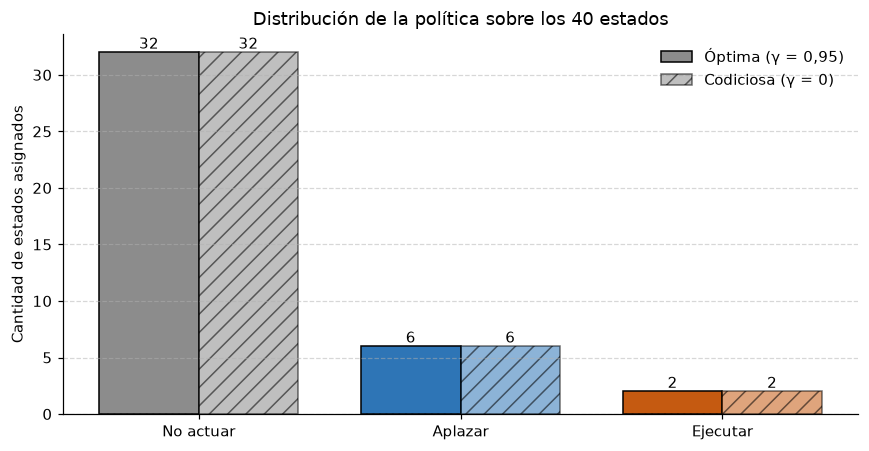

           Óptima (γ = 0,95)  Codiciosa (γ = 0)
No actuar                 32                 32
Aplazar                    6                  6
Ejecutar                   2                  2


'6'

In [10]:
# PASO 5.5 · Gráfica de distribución de la política (la pedida en el enunciado), óptima frente a codiciosa
cuenta = pd.DataFrame({"Óptima (γ = 0,95)": df_policy["Acción óptima (a)"].value_counts(),
                       "Codiciosa (γ = 0)": df_policy["Acción codiciosa"].value_counts()}).reindex(ACCIONES).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8, 4.2))
xx = np.arange(3); w = 0.38
b1 = ax.bar(xx - w/2, cuenta.iloc[:, 0], w, color=[COL[a] for a in ACCIONES], edgecolor="black", label=cuenta.columns[0])
b2 = ax.bar(xx + w/2, cuenta.iloc[:, 1], w, color=[COL[a] for a in ACCIONES], edgecolor="black", hatch="//", alpha=0.55, label=cuenta.columns[1])
ax.bar_label(b1); ax.bar_label(b2)
ax.set_xticks(xx, ACCIONES); ax.set_ylabel("Cantidad de estados asignados")
ax.set_title(f"Distribución de la política sobre los {len(STATES)} estados")
ax.legend(frameon=False); ax.grid(axis="y", ls="--", alpha=0.5)
fig.tight_layout(); fig.savefig(FIG / "R3_distribucion_politica.png"); plt.show()
print(cuenta)
for a in ACCIONES:
    reg(f"n_opt_{a}", int(cuenta.loc[a].iloc[0]), es(int(cuenta.loc[a].iloc[0]), 0))
    reg(f"n_cod_{a}", int(cuenta.loc[a].iloc[1]), es(int(cuenta.loc[a].iloc[1]), 0))
n_alto_libres = sum(1 for s in STATES if partes(s)[2] == 2 and s.endswith("-0"))
reg("n_alto_libres", n_alto_libres, es(n_alto_libres, 0))

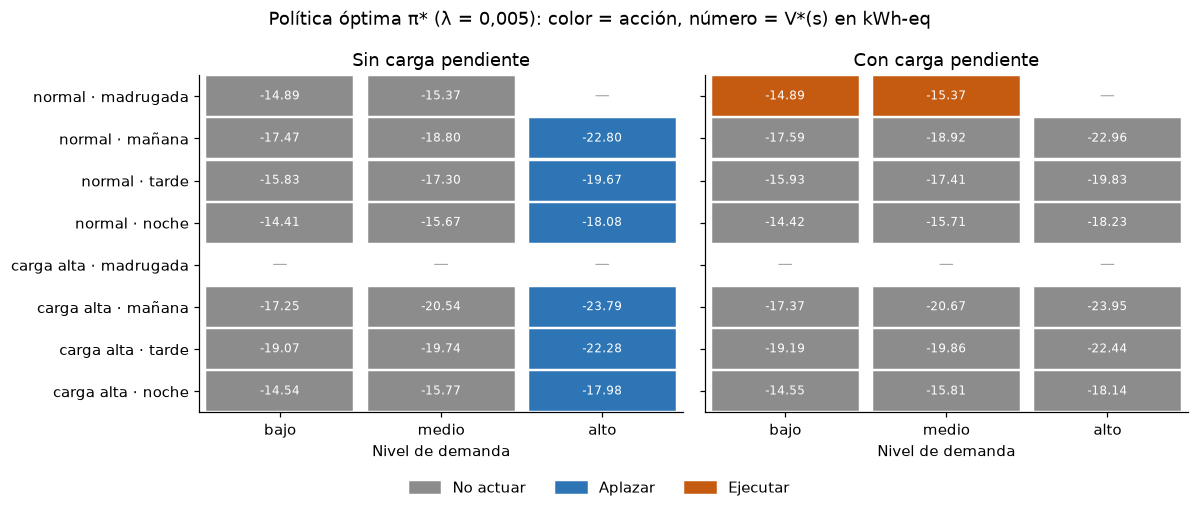

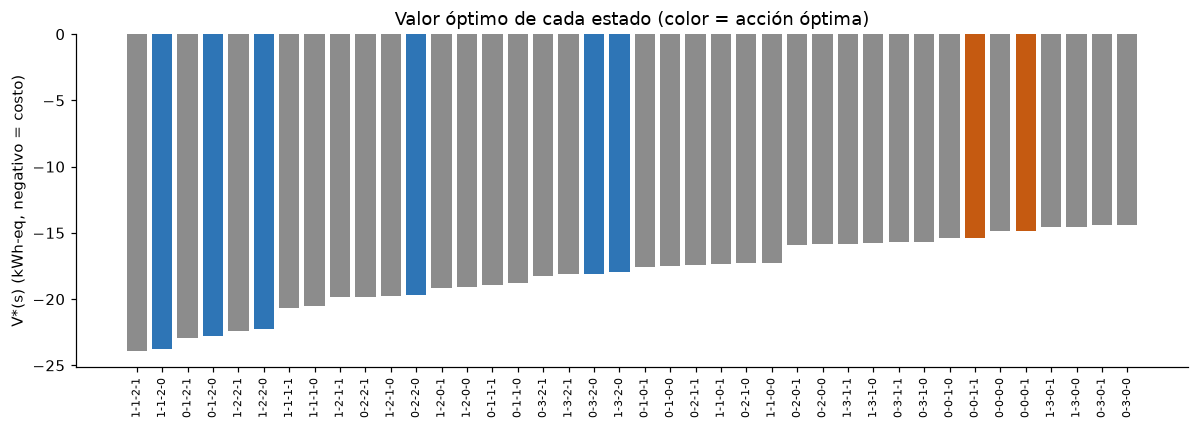

In [11]:
# Mapa de la política: cada estado con su acción, sin y con carga pendiente
cmap = {0: COL["No actuar"], 1: COL["Aplazar"], 2: COL["Ejecutar"]}
def mapa(pol, Vv, archivo, titulo):
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
    for k, p in enumerate((0, 1)):
        ax = axs[k]
        for t in (0, 1):
            for f in range(4):
                for n in range(3):
                    s = f"{t}-{f}-{n}-{p}"; i = t * 4 + f
                    if s in pol:
                        ax.add_patch(plt.Rectangle((n - .45, i - .45), .9, .9, color=cmap[pol[s]]))
                        ax.text(n, i, f"{Vv[s]:.2f}", ha="center", va="center", fontsize=8, color="white")
                    else:
                        ax.text(n, i, "—", ha="center", va="center", color="#999")
        ax.set_xlim(-.5, 2.5); ax.set_ylim(7.5, -.5)
        ax.set_xticks(range(3), [NIVEL_N[n] for n in range(3)])
        ax.set_yticks(range(8), [f"{TIPO_N[t]} · {FRANJA_N[f]}" for t in (0, 1) for f in range(4)])
        ax.set_title("Sin carga pendiente" if p == 0 else "Con carga pendiente")
        ax.set_xlabel("Nivel de demanda")
    handles = [plt.Rectangle((0, 0), 1, 1, color=COL[a]) for a in ACCIONES]
    fig.legend(handles, ACCIONES, loc="lower center", ncol=3, frameon=False)
    fig.suptitle(titulo)
    fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIG / archivo); plt.show()
mapa(politica, V, "R5_mapa_politica.png", "Política óptima π* (λ = 0,005): color = acción, número = V*(s) en kWh-eq")

# V*(s) por estado (como en el ejemplo de clase)
orden = sorted(STATES, key=lambda s: V[s])
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(orden)), [V[s] for s in orden], color=[cmap[politica[s]] for s in orden])
ax.set_xticks(range(len(orden)), [s for s in orden], rotation=90, fontsize=7)
ax.set_ylabel("V*(s) (kWh-eq, negativo = costo)"); ax.set_title("Valor óptimo de cada estado (color = acción óptima)")
fig.tight_layout(); fig.savefig(FIG / "R4_valores.png"); plt.show()

## PARTE 3 · La batalla de las políticas

### 3.1 · ¿Dónde se separa la política óptima de la codiciosa?

Las reglas de oro están en los estados donde π\* ≠ codiciosa. Para cada uno se descompone Q(s,a) en la recompensa
inmediata y el valor futuro descontado, y se muestran las horas esperadas hasta el valle.

Si no hay ninguno, mirar al futuro no cambió ninguna decisión con estos parámetros. En las fresas eso pasaba por
construcción; aquí es un resultado, y la sección 3.5 busca el perfil de persona en el que sí cambia.

In [12]:
difs = []
for s in STATES:
    if politica[s] != codiciosa[s]:
        q = q_valores(s, V, R_dict, P_dict)
        fila = {"Estado": s, "Descripción": describir(s), "π*": ACCIONES[politica[s]], "Codiciosa": ACCIONES[codiciosa[s]],
                "Horas hasta el valle": round(HORAS_VALLE[s[:-2]], 1)}
        for a in q:
            fila[f"R({ACCIONES[a]})"] = round(R_dict[s][a], 4)
            fila[f"Q({ACCIONES[a]})"] = round(q[a], 4)
        difs.append(fila)
df_difs = pd.DataFrame(difs)
print(f"Estados donde la política óptima y la codiciosa difieren: {len(df_difs)} de {len(STATES)}")
print(df_difs.to_string(index=False) if len(df_difs) else "(ninguno)")
reg("n_difs", len(df_difs), es(len(df_difs), 0))
df_difs.to_csv("estados_optima_vs_codiciosa.csv", index=False, encoding="utf-8")

# Resumen por franja: ¿en qué franjas aplaza cada política un pico sin carga pendiente?
res_fr = []
for f in (1, 2, 3):
    ss = [s for s in STATES if partes(s)[1] == f and partes(s)[2] == 2 and s.endswith("-0")]
    res_fr.append({"Franja": FRANJA_N[f], "Picos posibles": len(ss),
                   "Aplaza π*": sum(politica[s] == 1 for s in ss), "Aplaza codiciosa": sum(codiciosa[s] == 1 for s in ss)})
print(pd.DataFrame(res_fr).to_string(index=False))
for r_ in res_fr:
    reg(f"aplaza_opt_{r_['Franja']}", r_["Aplaza π*"], f"{r_['Aplaza π*']} de {r_['Picos posibles']}")
    reg(f"aplaza_cod_{r_['Franja']}", r_["Aplaza codiciosa"], f"{r_['Aplaza codiciosa']} de {r_['Picos posibles']}")

Estados donde la política óptima y la codiciosa difieren: 0 de 40
(ninguno)
Franja  Picos posibles  Aplaza π*  Aplaza codiciosa
mañana               2          2                 2
 tarde               2          2                 2
 noche               2          2                 2


### 3.2 · Repetición fuera de muestra: mayo con cada política

Se recorre hora por hora el mes que el modelo nunca vio. Lo exógeno (demanda, franja, tipo de día estimado) es real; la
política decide y sus acciones mueven ΔE de una hora a otra y abren o cierran la carga pendiente. El costo se cobra **en la
hora en que la energía se consume y a la tarifa de esa hora** (sin descuento ni contabilidad especial: es la cuenta real).
Contendientes:
- **No actuar** (el hogar tal cual).
- **Regla fija**: aplazar todo pico en punta y ejecutar al llegar la madrugada.
- **Codiciosa** (γ = 0).
- **π\*** (γ = 0,95).

Cada cifra de mayo va con su par de enero–abril, dentro de la muestra.

In [13]:
regla_fija = {}
for s in STATES:
    t, f, n = partes(s); p = int(s[-1])
    regla_fija[s] = 1 if (n == 2 and p == 0 and f != 0) else (2 if (p == 1 and f == 0) else 0)
POLITICAS = {"No actuar": {s: 0 for s in STATES}, "Regla fija": regla_fija, "Codiciosa": codiciosa, "π*": politica}

def repetir(pol, tramo, r_punta=R_PUNTA):
    p = 0; filas = []
    for row in tramo.itertuples():
        s = f"{row.x}-{p}"
        a = pol.get(s, 0)
        if s not in pol or not valida(s, a):
            a = 0                                                   # estado nunca visto → no actuar
        e = row.wh + (-DE if a == 1 else (DE if a == 2 else 0))
        p = 1 if a == 1 else (0 if a == 2 else p)
        filas.append({"dia": row.dia, "costo": tarifa(row.franja, r_punta) * e / 1000, "espera": p,
                      "aplaza": int(a == 1), "desconocido": int(s not in pol)})
    if p == 1:                                                      # cerrar cuentas: lo pendiente se ejecuta al final
        filas[-1]["costo"] += tarifa(tramo.franja.iloc[-1], r_punta) * DE / 1000
    return pd.DataFrame(filas).groupby("dia").sum()

def resumen(diarios, base):
    n = len(diarios)
    return {"Costo (kWh-eq/día)": diarios.costo.mean(), "Ahorro vs no actuar (%)": (1 - diarios.costo.sum() / base.costo.sum()) * 100,
            "Horas de espera/día": diarios.espera.mean(), "Aplazamientos/día": diarios.aplaza.mean(),
            "Espera por aplazamiento (h)": diarios.espera.sum() / max(diarios.aplaza.sum(), 1),
            "Objetivo (costo + λ·espera)/día": (diarios.costo + LAMBDA * diarios.espera).mean()}

DIARIOS = {}
tabla = []
for tramo_n, tramo in (("Enero–abril (dentro de muestra)", TR), ("Mayo (fuera de muestra)", TE)):
    base = repetir(POLITICAS["No actuar"], tramo)
    for nom, pol in POLITICAS.items():
        dd_ = repetir(pol, tramo); DIARIOS[(tramo_n, nom)] = dd_
        tabla.append({"Tramo": tramo_n, "Política": nom, **resumen(dd_, base)})
df_batalla = pd.DataFrame(tabla)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print(df_batalla.to_string(index=False))
claves = {"No actuar": "no", "Regla fija": "regla", "Codiciosa": "cod", "π*": "opt"}
for r_ in tabla:
    tk = "te" if r_["Tramo"].startswith("Mayo") else "tr"; k = claves[r_["Política"]]
    reg(f"costo_{k}_{tk}", r_["Costo (kWh-eq/día)"], es(r_["Costo (kWh-eq/día)"], 2) + " kWh-eq/día")
    reg(f"ahorro_{k}_{tk}", r_["Ahorro vs no actuar (%)"], es(r_["Ahorro vs no actuar (%)"], 2) + " %")
    reg(f"espera_{k}_{tk}", r_["Horas de espera/día"], es(r_["Horas de espera/día"], 1) + " h/día")
    reg(f"aplaz_{k}_{tk}", r_["Aplazamientos/día"], es(r_["Aplazamientos/día"], 2))
    reg(f"esperaxap_{k}_{tk}", r_["Espera por aplazamiento (h)"], es(r_["Espera por aplazamiento (h)"], 1) + " h")
print("Estados desconocidos visitados en mayo por π*:", int(DIARIOS[("Mayo (fuera de muestra)", "π*")].desconocido.sum()))

                          Tramo   Política  Costo (kWh-eq/día)  Ahorro vs no actuar (%)  Horas de espera/día  Aplazamientos/día  Espera por aplazamiento (h)  Objetivo (costo + λ·espera)/día
Enero–abril (dentro de muestra)  No actuar              20.370                    0.000                0.000              0.000                        0.000                           20.370
Enero–abril (dentro de muestra) Regla fija              20.248                    0.602                8.564              0.800                       10.705                           20.291
Enero–abril (dentro de muestra)  Codiciosa              20.248                    0.602                8.564              0.800                       10.705                           20.291
Enero–abril (dentro de muestra)         π*              20.248                    0.602                8.564              0.800                       10.705                           20.291
        Mayo (fuera de muestra)  No actuar        

                          Tramo   π* menos  Diferencia media (kWh-eq/día)  IC 95 % inf  IC 95 % sup ¿Se distingue?
Enero–abril (dentro de muestra)  No actuar                         -0.080       -0.118       -0.043             sí
Enero–abril (dentro de muestra) Regla fija                          0.000        0.000        0.000             no
Enero–abril (dentro de muestra)  Codiciosa                          0.000        0.000        0.000             no
        Mayo (fuera de muestra)  No actuar                         -0.078       -0.173        0.019             no
        Mayo (fuera de muestra) Regla fija                          0.000        0.000        0.000             no
        Mayo (fuera de muestra)  Codiciosa                          0.000        0.000        0.000             no
(Negativo = π* tiene menos costo + espera que el rival)


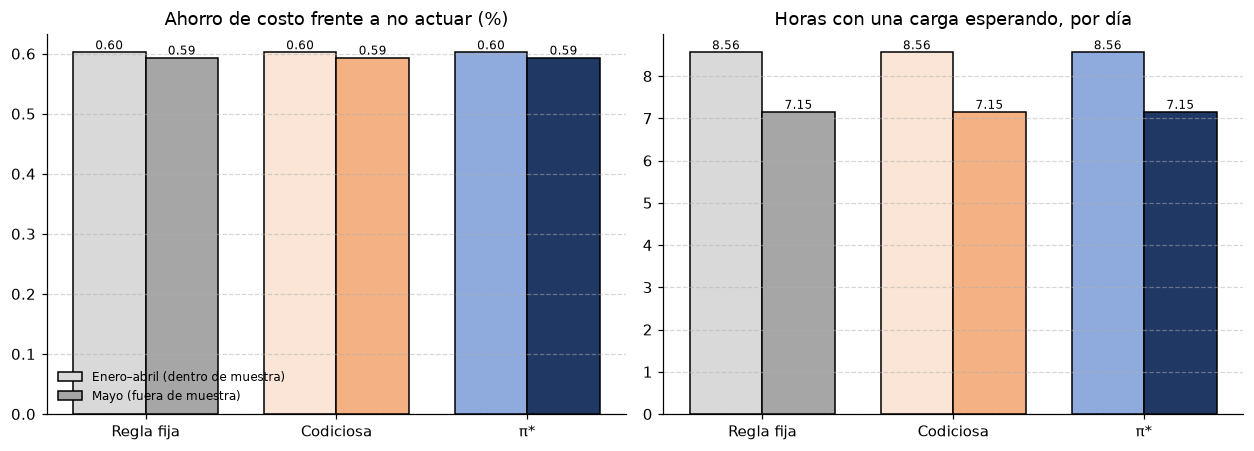

In [14]:
# Diferencias con rango plausible: bootstrap pareado por día (2.000 réplicas, semilla 42)
def bootstrap(a, b, n=2000, seed=RS):
    rng = np.random.default_rng(seed); dif = (a - b).values; k = len(dif)
    reps = np.array([dif[rng.integers(0, k, k)].mean() for _ in range(n)])
    return dif.mean(), np.percentile(reps, 2.5), np.percentile(reps, 97.5)
obj = lambda dd_: dd_.costo + LAMBDA * dd_.espera
filas_b = []
for tramo_n in ("Enero–abril (dentro de muestra)", "Mayo (fuera de muestra)"):
    tk = "te" if tramo_n.startswith("Mayo") else "tr"
    for rival, k in (("No actuar", "no"), ("Regla fija", "regla"), ("Codiciosa", "cod")):
        m_, lo, hi = bootstrap(obj(DIARIOS[(tramo_n, "π*")]), obj(DIARIOS[(tramo_n, rival)]))
        filas_b.append({"Tramo": tramo_n, "π* menos": rival, "Diferencia media (kWh-eq/día)": m_, "IC 95 % inf": lo, "IC 95 % sup": hi,
                        "¿Se distingue?": "sí" if (hi < 0 or lo > 0) else "no"})
        reg(f"boot_{k}_{tk}", m_, f"{es(m_, 3)} kWh-eq/día (IC {es(lo, 3)} a {es(hi, 3)})")
        reg(f"boot_{k}_{tk}_sig", "sí" if (hi < 0 or lo > 0) else "no", "sí" if (hi < 0 or lo > 0) else "no")
print(pd.DataFrame(filas_b).to_string(index=False))
print("(Negativo = π* tiene menos costo + espera que el rival)")

# Gráfica de la batalla
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.2))
noms = list(POLITICAS)[1:]
for j, (col, tit) in enumerate((("Ahorro vs no actuar (%)", "Ahorro de costo frente a no actuar (%)"),
                                 ("Horas de espera/día", "Horas con una carga esperando, por día"))):
    ax = axs[j]
    for i, tramo_n in enumerate(("Enero–abril (dentro de muestra)", "Mayo (fuera de muestra)")):
        vals = [df_batalla[(df_batalla.Tramo == tramo_n) & (df_batalla.Política == nmb)][col].iloc[0] for nmb in noms]
        bb = ax.bar(np.arange(len(noms)) + (i - .5) * .38, vals, .38, color=["#A6A6A6", "#F4B183", AZUL][:len(noms)] if i else ["#D9D9D9", "#FBE5D6", "#8FAADC"][:len(noms)],
                    edgecolor="black", label=tramo_n)
        ax.bar_label(bb, fmt="%.2f", fontsize=8)
    ax.set_xticks(range(len(noms)), noms); ax.set_title(tit); ax.grid(axis="y", ls="--", alpha=.5)
axs[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "R6_batalla.png"); plt.show()

### 3.3 · Sensibilidad: ¿cuánto tiene que valer la espera para que aplazar deje de convenir?

Se barre λ (costo de una hora de espera) y la tarifa de punta. Para cada par se resuelve el MDP de nuevo y se mide en
mayo. Esto responde la decisión 3 de la apertura: λ es el control que Shiro le daría a la persona.

Tarifa punta  1.000  1.250  1.500  2.000
λ                                       
0.000             0      6      6      6
0.002             0      6      6      6
0.005             0      5      6      6
0.010             0      3      5      6
0.020             0      0      3      5
Tarifa punta  1.000  1.250  1.500  2.000
λ                                       
0.000         0.000  0.350  0.590  0.910
0.002         0.000  0.350  0.590  0.910
0.005         0.000  0.330  0.590  0.910
0.010         0.000  0.290  0.560  0.910
0.020         0.000  0.000  0.500  0.870


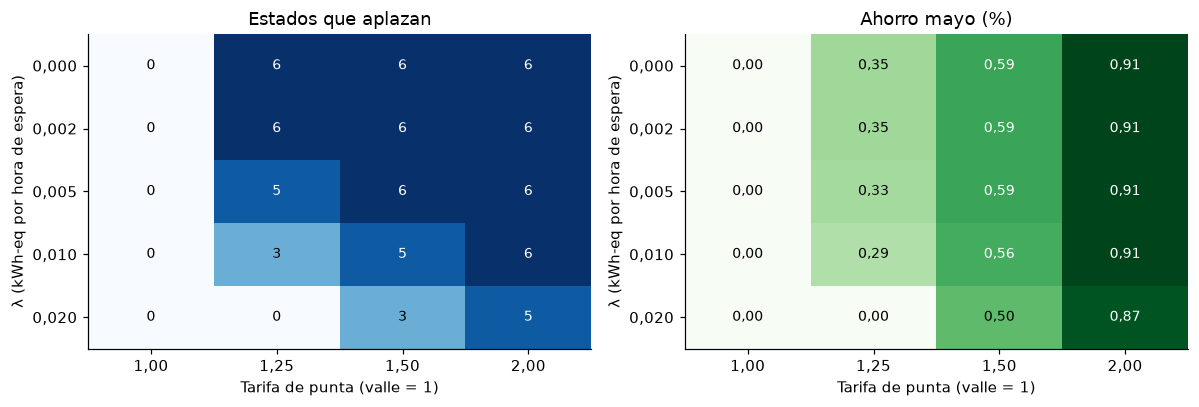

In [15]:
sens = []
base_te = repetir(POLITICAS["No actuar"], TE)
for lam in LAMBDAS:
    for rp in R_PUNTAS:
        Rk = construir_R(r_punta=rp, lam=lam); Vk, _ = iteracion_valor(Rk, P_dict); pk = extraer_politica(Vk, Rk, P_dict)
        dte = repetir(pk, TE, r_punta=rp); bte = repetir(POLITICAS["No actuar"], TE, r_punta=rp)
        n_ap = sum(pk[s] == 1 for s in STATES)
        sens.append({"λ": lam, "Tarifa punta": rp, "Estados que aplazan": n_ap,
                     "Ahorro mayo (%)": (1 - dte.costo.sum() / bte.costo.sum()) * 100, "Espera mayo (h/día)": dte.espera.mean()})
df_sens = pd.DataFrame(sens)
print(df_sens.pivot(index="λ", columns="Tarifa punta", values="Estados que aplazan").to_string())
print(df_sens.pivot(index="λ", columns="Tarifa punta", values="Ahorro mayo (%)").round(2).to_string())
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, cm_ in zip(axs, ("Estados que aplazan", "Ahorro mayo (%)"), ("Blues", "Greens")):
    M = df_sens.pivot(index="λ", columns="Tarifa punta", values=col)
    ax.imshow(M.values, cmap=cm_, aspect="auto")
    tope = np.nanmax(M.values) if np.nanmax(M.values) > 0 else 1
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.values[i, j]:.0f}" if col.startswith("Estados") else es(M.values[i, j], 2), ha="center", va="center",
                    fontsize=9, color="white" if M.values[i, j] > 0.55 * tope else "black")
    ax.set_xticks(range(M.shape[1]), [es(v, 2) for v in M.columns]); ax.set_xlabel("Tarifa de punta (valle = 1)")
    ax.set_yticks(range(M.shape[0]), [es(v, 3) for v in M.index]); ax.set_ylabel("λ (kWh-eq por hora de espera)")
    ax.set_title(col)
fig.tight_layout(); fig.savefig(FIG / "R7_sensibilidad.png"); plt.show()
for _, r_ in df_sens.iterrows():
    tag = f"{r_['λ']}_{r_['Tarifa punta']}".replace(".", "p")
    reg(f"sens_nap_{tag}", int(r_["Estados que aplazan"]), es(int(r_["Estados que aplazan"]), 0))
    reg(f"sens_ahorro_{tag}", float(r_["Ahorro mayo (%)"]), es(float(r_["Ahorro mayo (%)"]), 2) + " %")

### 3.4 · Prueba de cordura: tarifa plana y contabilidad ingenua

Con tarifa plana (punta = valle) **no hay nada que ganar aplazando**, así que un MDP bien planteado no debe aplazar
nunca. Se compara con la contabilidad ingenua, que cobra la energía aplazada completa al ejecutarla, y con el descuento γ
para ver cuánto cambia la política.

In [16]:
cordura = []
for contab in ("corregida", "ingenua"):
    for rp in (1.0, R_PUNTA):
        Rk = construir_R(r_punta=rp, contabilidad=contab); Vk, _ = iteracion_valor(Rk, P_dict); pk = extraer_politica(Vk, Rk, P_dict)
        dte = repetir(pk, TE, r_punta=rp); bte = repetir(POLITICAS["No actuar"], TE, r_punta=rp)
        cordura.append({"Contabilidad": contab, "Tarifa punta": rp, "Estados que aplazan": sum(pk[s] == 1 for s in STATES),
                        "Ahorro mayo (%)": (1 - dte.costo.sum() / bte.costo.sum()) * 100, "Espera mayo (h/día)": dte.espera.mean()})
        reg(f"cordura_{contab}_{str(rp).replace('.', 'p')}_nap", sum(pk[s] == 1 for s in STATES), es(sum(pk[s] == 1 for s in STATES), 0))
        reg(f"cordura_{contab}_{str(rp).replace('.', 'p')}_ahorro", (1 - dte.costo.sum() / bte.costo.sum()) * 100,
            es((1 - dte.costo.sum() / bte.costo.sum()) * 100, 2) + " %")
        reg(f"cordura_{contab}_{str(rp).replace('.', 'p')}_espera", dte.espera.mean(), es(dte.espera.mean(), 1) + " h/día")
print(pd.DataFrame(cordura).to_string(index=False))
assert pd.DataFrame(cordura).query("Contabilidad == 'corregida' and `Tarifa punta` == 1.0")["Estados que aplazan"].iloc[0] == 0, \
    "Con tarifa plana y contabilidad corregida el MDP no debería aplazar nunca"

gam = []
for g in GAMMAS:
    Vg, itg = iteracion_valor(R_dict, P_dict, gamma=g); pg = extraer_politica(Vg, R_dict, P_dict, gamma=g)
    dte = repetir(pg, TE)
    gam.append({"γ": g, "Iteraciones": itg, "Estados que aplazan": sum(pg[s] == 1 for s in STATES),
                "Ahorro mayo (%)": (1 - dte.costo.sum() / base_te.costo.sum()) * 100, "Espera mayo (h/día)": dte.espera.mean()})
    reg(f"gamma_{str(g).replace('.', 'p')}_nap", sum(pg[s] == 1 for s in STATES), es(sum(pg[s] == 1 for s in STATES), 0))
print(pd.DataFrame(gam).to_string(index=False))

Contabilidad  Tarifa punta  Estados que aplazan  Ahorro mayo (%)  Espera mayo (h/día)
   corregida         1.000                    0            0.000                0.000
   corregida         1.500                    6            0.594                7.154
     ingenua         1.000                    6            0.000               23.385
     ingenua         1.500                    6            0.000               23.385


    γ  Iteraciones  Estados que aplazan  Ahorro mayo (%)  Espera mayo (h/día)
0.000            2                    6            0.594                7.154
0.500           21                    6            0.594                7.154
0.900          131                    6            0.594                7.154
0.950          268                    6            0.594                7.154
0.990         1359                    5            0.562                5.923


### 3.5 · Cuando la espera cuesta: el perfil «exigente» (λ = 0,02)

Con λ = 0,005 (persona paciente) la política óptima coincide con la codiciosa en todos los estados: lo que se ahorra al
aplazar supera con holgura lo que cuesta esperar, así que mirar al futuro no cambia ninguna decisión. La sensibilidad
muestra que eso deja de ser así cuando la espera vale más. Aquí se resuelve el MDP para una persona que valora su tiempo
cuatro veces más (λ = 0,02). En ese perfil aparecen los estados donde π\* y la codiciosa discrepan; ahí están las reglas
de oro.

λ = 0.02: convergencia en 268 iteraciones
P(otro pico en punta antes del valle) desde cada pico en punta: {'normal · mañana · alto': np.float64(0.9), 'normal · tarde · alto': np.float64(0.67), 'normal · noche · alto': np.float64(0.43), 'carga alta · mañana · alto': np.float64(0.94), 'carga alta · tarde · alto': np.float64(0.87), 'carga alta · noche · alto': np.float64(0.23)}
Horas de espera que compensa un aplazamiento ((r−1)·ΔE/λ): {0.005: np.float64(31.0), 0.02: np.float64(7.8)}
normal · tarde · alto: π*=Aplazar · Q(no)=-19.8062 Q(aplazar)=-19.8031 · horas al valle 10.2 · P(otro pico) 0.67
carga alta · tarde · alto: π*=No actuar · Q(no)=-22.4088 Q(aplazar)=-22.4161 · horas al valle 11.9 · P(otro pico) 0.87
normal · noche · alto: π*=Aplazar · Q(no)=-18.2279 Q(aplazar)=-18.2038 · horas al valle 7.1 · P(otro pico) 0.43
carga alta · noche · alto: π*=Aplazar · Q(no)=-18.1399 Q(aplazar)=-18.1037 · horas al valle 6.6 · P(otro pico) 0.23
normal · tarde · alto · con carga pendiente: π*=No act

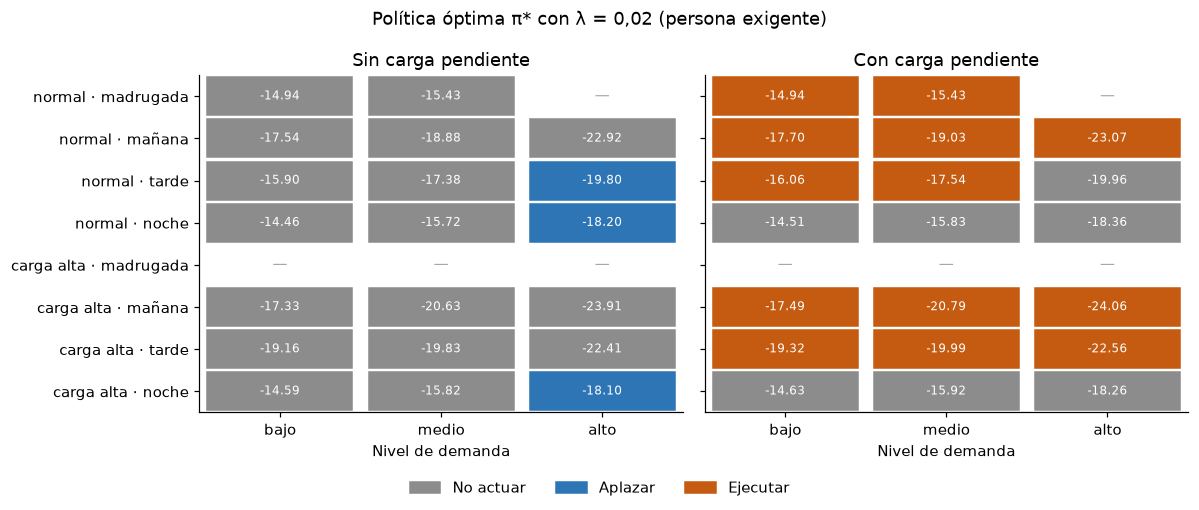

                          Tramo   Política  Costo (kWh-eq/día)  Ahorro vs no actuar (%)  Horas de espera/día  Aplazamientos/día  Espera por aplazamiento (h)  Objetivo (costo + λ·espera)/día
Enero–abril (dentro de muestra)  No actuar              20.370                    0.000                0.000              0.000                        0.000                           20.370
Enero–abril (dentro de muestra) Regla fija              20.248                    0.602                8.564              0.800                       10.705                           20.419
Enero–abril (dentro de muestra)  Codiciosa              20.248                    0.602                8.564              0.800                       10.705                           20.419
Enero–abril (dentro de muestra)         π*              20.270                    0.492                4.145              0.800                        5.182                           20.353
        Mayo (fuera de muestra)  No actuar        

In [17]:
LAMBDA_EX = 0.02
R_ex = construir_R(lam=LAMBDA_EX)
V_ex, it_ex = iteracion_valor(R_ex, P_dict); pol_ex = extraer_politica(V_ex, R_ex, P_dict)
V0_ex, _ = iteracion_valor(R_ex, P_dict, gamma=0.0); cod_ex = extraer_politica(V0_ex, R_ex, P_dict, gamma=0.0)
print(f"λ = {LAMBDA_EX}: convergencia en {it_ex} iteraciones")
# Probabilidad de que llegue OTRO pico en punta antes del valle (cadena contada, estado actual excluido)
punta_alta = [x for x in X_EXO if partes(x)[2] == 2 and partes(x)[1] != 0]
libres = [x for x in X_EXO if partes(x)[1] != 0 and x not in punta_alta]
A_ = np.array([[P_EXO[x].get(x2, 0) for x2 in libres] for x in libres])
b_ = np.array([sum(P_EXO[x].get(x2, 0) for x2 in punta_alta) for x in libres])
h_ = dict(zip(libres, np.linalg.solve(np.eye(len(libres)) - A_, b_)))
g_ = lambda x2: 1.0 if x2 in punta_alta else (0.0 if partes(x2)[1] == 0 else h_[x2])
P_OTRO_PICO = {x: sum(pr * g_(x2) for x2, pr in P_EXO[x].items()) for x in X_EXO}
print("P(otro pico en punta antes del valle) desde cada pico en punta:",
      {describir(x): round(P_OTRO_PICO[x], 2) for x in punta_alta})
for x in punta_alta:
    reg(f"p_otro_pico_{x}", P_OTRO_PICO[x], es(P_OTRO_PICO[x] * 100, 0) + " %")
    reg(f"horas_valle_x_{x}", HORAS_VALLE[x], es(HORAS_VALLE[x]) + " h")
HORAS_EQ = {lam: (R_PUNTA - 1) * DE / 1000 / lam for lam in (LAMBDA, LAMBDA_EX)}
print("Horas de espera que compensa un aplazamiento ((r−1)·ΔE/λ):", {lam: round(h, 1) for lam, h in HORAS_EQ.items()})
reg("horas_eq_paciente", HORAS_EQ[LAMBDA], es(HORAS_EQ[LAMBDA]) + " h"); reg("horas_eq_exigente", HORAS_EQ[LAMBDA_EX], es(HORAS_EQ[LAMBDA_EX]) + " h")
reg("ganancia_aplazar", (R_PUNTA - 1) * DE / 1000, es((R_PUNTA - 1) * DE / 1000, 3) + " kWh-eq")

reglas = []
for s in STATES:
    if pol_ex[s] != cod_ex[s]:
        q = q_valores(s, V_ex, R_ex, P_dict)
        fut = {a: GAMMA * sum(pr * V_ex[s2] for s2, pr in P_dict[s][a].items()) for a in q}
        reglas.append({"Estado": s, "Descripción": describir(s), "π* (λ=0,02)": ACCIONES[pol_ex[s]], "Codiciosa": ACCIONES[cod_ex[s]],
                       "Horas hasta el valle": round(HORAS_VALLE[s[:-2]], 1), "P(otro pico antes del valle)": round(P_OTRO_PICO[s[:-2]], 2),
                       "R(No actuar)": R_ex[s][0], "R(Aplazar)": R_ex[s].get(1, np.nan), "R(Ejecutar)": R_ex[s].get(2, np.nan),
                       "γΣPV (No actuar)": fut[0], "γΣPV (Aplazar)": fut.get(1, np.nan), "γΣPV (Ejecutar)": fut.get(2, np.nan),
                       "Q(No actuar)": q[0], "Q(Aplazar)": q.get(1, np.nan), "Q(Ejecutar)": q.get(2, np.nan)})
# Los dos picos de tarde (normal y carga alta), con su Q, para contrastar la regla del cupo
for s in ("0-2-2-0", "1-2-2-0", "0-3-2-0", "1-3-2-0"):
    if s in STATES:
        q = q_valores(s, V_ex, R_ex, P_dict)
        print(f"{describir(s)}: π*={ACCIONES[pol_ex[s]]} · Q(no)={q[0]:.4f} Q(aplazar)={q[1]:.4f} · horas al valle {HORAS_VALLE[s[:-2]]:.1f} · P(otro pico) {P_OTRO_PICO[s[:-2]]:.2f}")
        reg(f"ex_Qno_{s}", q[0], es(q[0], 3)); reg(f"ex_Qap_{s}", q[1], es(q[1], 3)); reg(f"ex_dQ_{s}", q[1] - q[0], es(q[1] - q[0], 3))
        reg(f"ex_pol_{s}", ACCIONES[pol_ex[s]], ACCIONES[pol_ex[s]])
for s in ("0-2-2-1", "0-2-1-1", "0-3-1-1"):
    q = q_valores(s, V_ex, R_ex, P_dict)
    print(f"{describir(s)}: π*={ACCIONES[pol_ex[s]]} · Q(no)={q[0]:.4f} Q(ejecutar)={q[2]:.4f}")
    reg(f"ex_Qno_{s}", q[0], es(q[0], 3)); reg(f"ex_Qej_{s}", q[2], es(q[2], 3)); reg(f"ex_pol_{s}", ACCIONES[pol_ex[s]], ACCIONES[pol_ex[s]])
df_reglas = pd.DataFrame(reglas)
print(f"Estados donde π* y la codiciosa discrepan con λ = 0,02: {len(df_reglas)}")
print(df_reglas.round(4).to_string(index=False))
df_reglas.to_csv("reglas_de_oro_lambda_0p02.csv", index=False, encoding="utf-8")
reg("ex_n_difs", len(df_reglas), es(len(df_reglas), 0))
reg("ex_n_aplaza", sum(pol_ex[s] == 1 for s in STATES), es(sum(pol_ex[s] == 1 for s in STATES), 0))
reg("ex_n_aplaza_cod", sum(cod_ex[s] == 1 for s in STATES), es(sum(cod_ex[s] == 1 for s in STATES), 0))
for i, r_ in df_reglas.iterrows():
    k = r_["Estado"]
    reg(f"regla_{k}_desc", r_["Descripción"], r_["Descripción"])
    reg(f"regla_{k}_horas", r_["Horas hasta el valle"], es(r_["Horas hasta el valle"]) + " h")
    reg(f"regla_{k}_Rno", r_["R(No actuar)"], es(r_["R(No actuar)"], 3)); reg(f"regla_{k}_Rap", r_["R(Aplazar)"], es(r_["R(Aplazar)"], 3))
    reg(f"regla_{k}_Qno", r_["Q(No actuar)"], es(r_["Q(No actuar)"], 3)); reg(f"regla_{k}_Qap", r_["Q(Aplazar)"], es(r_["Q(Aplazar)"], 3))
    if k.endswith("-0"):
        reg(f"regla_{k}_ganancia_inm", r_["R(Aplazar)"] - r_["R(No actuar)"], es(r_["R(Aplazar)"] - r_["R(No actuar)"], 3))
        reg(f"regla_{k}_costo_fut", r_["γΣPV (No actuar)"] - r_["γΣPV (Aplazar)"], es(r_["γΣPV (No actuar)"] - r_["γΣPV (Aplazar)"], 3))
    else:
        reg(f"regla_{k}_Rej", r_["R(Ejecutar)"], es(r_["R(Ejecutar)"], 3)); reg(f"regla_{k}_Qej", r_["Q(Ejecutar)"], es(r_["Q(Ejecutar)"], 3))
        reg(f"regla_{k}_costo_inm_ej", r_["R(No actuar)"] - r_["R(Ejecutar)"], es(r_["R(No actuar)"] - r_["R(Ejecutar)"], 3))
        reg(f"regla_{k}_ganancia_fut_ej", r_["γΣPV (Ejecutar)"] - r_["γΣPV (No actuar)"], es(r_["γΣPV (Ejecutar)"] - r_["γΣPV (No actuar)"], 3))

# Qué hace π* con λ = 0,02 en cada franja (picos sin carga pendiente)
for f in (1, 2, 3):
    ss = [s for s in STATES if partes(s)[1] == f and partes(s)[2] == 2 and s.endswith("-0")]
    print(f"{FRANJA_N[f]}: aplaza en {[describir(s) for s in ss if pol_ex[s] == 1]}")
mapa(pol_ex, V_ex, "R8_mapa_politica_exigente.png", "Política óptima π* con λ = 0,02 (persona exigente)")

# Batalla con λ = 0,02
POL_EX = {"No actuar": {s: 0 for s in STATES}, "Regla fija": regla_fija, "Codiciosa": cod_ex, "π*": pol_ex}
tabla_ex = []; DIARIOS_EX = {}
for tramo_n, tramo in (("Enero–abril (dentro de muestra)", TR), ("Mayo (fuera de muestra)", TE)):
    base = repetir(POL_EX["No actuar"], tramo)
    for nom, pol in POL_EX.items():
        dd_ = repetir(pol, tramo); DIARIOS_EX[(tramo_n, nom)] = dd_
        rr = resumen(dd_, base); rr["Objetivo (costo + λ·espera)/día"] = (dd_.costo + LAMBDA_EX * dd_.espera).mean()
        tabla_ex.append({"Tramo": tramo_n, "Política": nom, **rr})
df_bex = pd.DataFrame(tabla_ex)
print(df_bex.to_string(index=False))
for r_ in tabla_ex:
    tk = "te" if r_["Tramo"].startswith("Mayo") else "tr"; k = claves[r_["Política"]]
    reg(f"ex_ahorro_{k}_{tk}", r_["Ahorro vs no actuar (%)"], es(r_["Ahorro vs no actuar (%)"], 2) + " %")
    reg(f"ex_espera_{k}_{tk}", r_["Horas de espera/día"], es(r_["Horas de espera/día"], 1) + " h/día")
    reg(f"ex_aplaz_{k}_{tk}", r_["Aplazamientos/día"], es(r_["Aplazamientos/día"], 2))
    reg(f"ex_obj_{k}_{tk}", r_["Objetivo (costo + λ·espera)/día"], es(r_["Objetivo (costo + λ·espera)/día"], 3) + " kWh-eq/día")
obj_ex = lambda dd_: dd_.costo + LAMBDA_EX * dd_.espera
for tramo_n in ("Enero–abril (dentro de muestra)", "Mayo (fuera de muestra)"):
    tk = "te" if tramo_n.startswith("Mayo") else "tr"
    for rival, k in (("No actuar", "no"), ("Codiciosa", "cod")):
        m_, lo, hi = bootstrap(obj_ex(DIARIOS_EX[(tramo_n, "π*")]), obj_ex(DIARIOS_EX[(tramo_n, rival)]))
        sig_ = "sí" if (hi < 0 or lo > 0) else "no"
        print(f"{tramo_n} · π* menos {rival}: {m_:.4f} kWh-eq/día (IC {lo:.4f} a {hi:.4f}) → ¿se distingue? {sig_}")
        reg(f"ex_boot_{k}_{tk}", m_, f"{es(m_, 3)} kWh-eq/día (IC {es(lo, 3)} a {es(hi, 3)})")
        reg(f"ex_boot_{k}_{tk}_sig", sig_, sig_)

## Exportación de cifras

`cifras.json` es la fuente única del documento y de la presentación.

In [18]:
CIFRAS_META = {"generado": time.strftime("%Y-%m-%d %H:%M"), "parametros": {"GAMMA": GAMMA, "THETA": THETA, "R_PUNTA": R_PUNTA,
               "F_DESPL": F_DESPL, "LAMBDA": LAMBDA, "UMBRAL": UMBRAL, "NIVEL_BAJO": NIVEL_BAJO, "HORA_TIPO": HORA_TIPO,
               "CORTE": str(CORTE.date())}}
Path("cifras.json").write_text(json.dumps({"meta": CIFRAS_META, "cifras": CIFRAS}, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"cifras.json: {len(CIFRAS)} cifras · figuras: {sorted(p.name for p in FIG.glob('R*.png'))}")

cifras.json: 370 cifras · figuras: ['R1_justificacion.png', 'R2_cobertura.png', 'R3_distribucion_politica.png', 'R4_valores.png', 'R5_mapa_politica.png', 'R6_batalla.png', 'R7_sensibilidad.png', 'R8_mapa_politica_exigente.png']
